# GC-AI quickstart

A diagram to SBOL3, and the result into a registry. The same work the
scripts in this directory do, with the detections on screen.

Needs a running stack and `uv sync --extra dev --extra db` in `client/`.
The last section also needs an [SBOL DB](https://github.com/marpaia/sbol-db)
registry.

In [1]:
import sys
from pathlib import Path

from IPython.display import Image, display

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs" / "examples").is_dir())
sys.path.insert(0, str(REPO_ROOT / "examples"))

import image_to_sbol
import publish_to_registry
from gcai import GCAIClient

CIRCUIT = REPO_ROOT / "docs" / "examples" / "YES GATE" / "YES-GATE-CIRCUIT.png"
NAMESPACE = "http://sbols.org/unspecified_namespace"
OUT = Path("/tmp/gcai-quickstart")

client = GCAIClient("http://localhost:5001")
client.health()

True

## What the detector sees

The input is a photograph of a pen-on-paper drawing. `run` prints the
glyphs in 5' to 3' order and writes the image with the boxes drawn on it.

In [2]:
summary = image_to_sbol.run(
    client,
    CIRCUIT,
    name="YesGate",
    namespace=NAMESPACE,
    out=OUT,
    annotated=OUT / "annotated.png",
)

2 glyphs in YES-GATE-CIRCUIT.png
   1. promoter               Promoter               [55, 164, 110, 234]
   2. ribosome-entry-site    RBS                    [115, 186, 163, 230]
detections drawn on /tmp/gcai-quickstart/annotated.png
wrote /tmp/gcai-quickstart/YesGate.xml
built YesGate from 2 parts: promoter_1, rbs_1
2 of them carry no sequence, so the document records their role and their place in the order, and the parent's sequence is the assembly scars between them. GenBank and FASTA need bases, so only the SBOL3 was written.


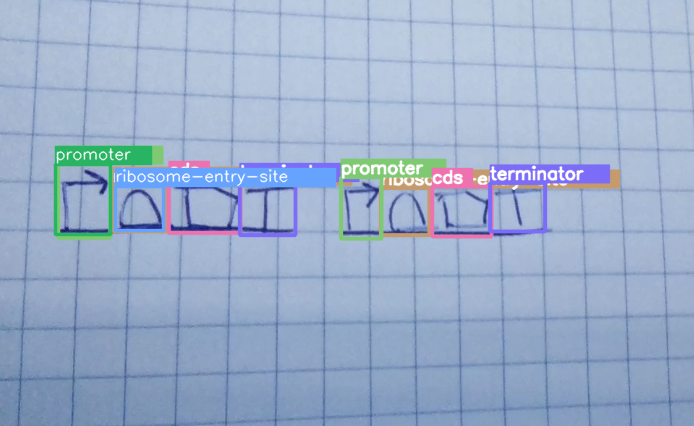

In [3]:
display(Image(filename=str(OUT / "annotated.png")))

The circuit drawn there has eight parts. Two were found. The boxes show
which, and `docs/examples/README.md` has the count for each committed
example. Detection is a starting point, not the design.

A diagram also says nothing about which registry parts it draws, so each
part is named after its role and carries no sequence. The document records
the role and the position, which is what was drawn.

In [4]:
summary.parts, summary.without_sequence, [p.name for p in summary.written]

(['promoter_1', 'rbs_1'], ['promoter_1', 'rbs_1'], ['YesGate.xml'])

## Naming the parts

One name per part, in the same order, binds them to parts the service's
registry holds. Their sequences come with them, so GenBank and FASTA can
be produced as well. An empty entry falls back to the role.

In [5]:
named = image_to_sbol.run(
    client,
    CIRCUIT,
    name="YesGateNamed",
    namespace=NAMESPACE,
    names=["BBa_R0010", "BBa_B0034"],
    out=OUT,
)

2 glyphs in YES-GATE-CIRCUIT.png
   1. promoter               Promoter               [55, 164, 110, 234]
   2. ribosome-entry-site    RBS                    [115, 186, 163, 230]


wrote /tmp/gcai-quickstart/YesGateNamed.xml
wrote /tmp/gcai-quickstart/YesGateNamed.gb
wrote /tmp/gcai-quickstart/YesGateNamed.fasta
built YesGateNamed from 2 parts: BBa_R0010, BBa_B0034


In [6]:
print((OUT / "YesGateNamed.fasta").read_text())

>BBa_B0034 RBS (Elowitz 1999) -- defines RBS efficiency
aaagaggagaaa
>BBa_R0010 promoter (lacI regulated)
caatacgcaaaccgcctctccccgcgcgttggccgattcattaatgcagctggcacgaca
ggtttcccgactggaaagcgggcagtgagcgcaacgcaattaatgtgagttagctcactc
attaggcaccccaggctttacactttatgcttccggctcgtatgttgtgtggaattgtga
gcggataacaatttcacaca
>YesGateNamed
caatacgcaaaccgcctctccccgcgcgttggccgattcattaatgcagctggcacgaca
ggtttcccgactggaaagcgggcagtgagcgcaacgcaattaatgtgagttagctcactc
attaggcaccccaggctttacactttatgcttccggctcgtatgttgtgtggaattgtga
gcggataacaatttcacacatactagagaaagaggagaaa



## Into a registry

The registry holds SBOL3, validates every import and keeps the graph
whatever the validator says. It serves an object in either SBOL
vocabulary, so the SBOL2 form below is a fetch, not a local conversion.

This writes to a service other people can read, which is why the script's
command line asks for `--yes`.

In [7]:
publish_to_registry.run(
    "http://127.0.0.1:8899",
    OUT / "YesGateNamed.xml",
    iri="https://gc-ai.example/designs/quickstart",
    design="YesGateNamed",
    namespace=NAMESPACE,
    overwrite=1,
)

published YesGateNamed.xml as https://gc-ai.example/designs/quickstart
  19 objects, 137 triples
  validation failed, 2 issues
  the import is kept either way; the registry records the issues against the graph
read http://sbols.org/unspecified_namespace/YesGateNamed back
  3669 bytes of SBOL3, naming the v3 vocabulary: True
  7026 bytes of SBOL2, which does not: True


In [8]:
client.close()

## From an agent

`gcai-mcp` does the first part of this as a single MCP tool call:

```sh
claude mcp add --transport stdio gc-ai --scope project -- \
  uv run --with "gc-ai-client[mcp]" gcai-mcp --url http://localhost:5001 --allow-root .
```

The MCP section of [`../client/README.md`](../client/README.md) has the rest.